In [1]:
import pandas as pd
import numpy as np
import random
import time
import pickle
import os
import sys

sys.path.append(os.path.abspath('..'))

from sklearn.model_selection import StratifiedKFold
from IPython.display import display

from utils.graphs import plot_confusion_matrix
from utils.util import evaluate_predictions, cross_evaluate
from utils.models import available_models, get_model


print("Pandas version: {}".format(pd.__version__))
print("NumPy version: {}".format(np.__version__))

seed = 42
np.random.seed(seed)
random.seed(seed)

Pandas version: 2.2.2
NumPy version: 2.0.1


# Load the data

Loads the manually extracted flows using latest CICFlowMeter

In [13]:
df = pd.read_parquet("../../data/CICIDS2017_improved/clean/tuesday-latest.parquet")

In [9]:
df.Label.value_counts()

Label
BENIGN         302280
FTP-Patator      3991
SSH-Patator      2961
Name: count, dtype: int64

# Prepare for Evaluation

In [4]:
result_dir = "../results/cicids2017-latest/baseline"
if not os.path.exists(result_dir):
    os.makedirs(result_dir)

In [14]:
# We are not interested in the FTP bruteforce samples from CICIDS2017
df = df[df['Label'] != 'FTP-Patator']
X, y = df.drop(columns=["Label"]), df["Label"].map(lambda x: 0 if x == "BENIGN" else 1)
del df

In [11]:
y.value_counts()

Label
0    302280
1      2961
Name: count, dtype: int64

# Baseline Evaluation

Identical for all datasets.

Evaluating model: decision_tree


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,6.593698,0.112890,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2368}",244192.000000,"[[241824, 0], [0, 2368]]",0.033037,0.998311,0.996627,1.000000,0.999967,1.000000,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [2, 591]]"
1,4.703703,0.097230,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.027850,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,6.941519,0.100184,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.027023,0.995773,0.994932,0.996616,0.999918,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [3, 589]]"
3,6.777837,0.094603,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.026859,0.999156,1.000000,0.998314,0.999984,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [0, 592]]"
4,8.356608,0.090440,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.026837,0.995773,0.994932,0.996616,0.999918,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [3, 589]]"
mean,6.674673,0.099069,1.0,1.0,1.0,1.0,1.0,NaN,244192.800000,NaN,0.028321,0.997803,0.997298,0.998309,0.999957,0.999983,NaN,61048.200000,NaN
std,1.304036,0.008515,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.002669,0.001946,0.002561,0.001692,0.000038,0.000017,NaN,0.447214,NaN


Aggregated test confusion matrix:


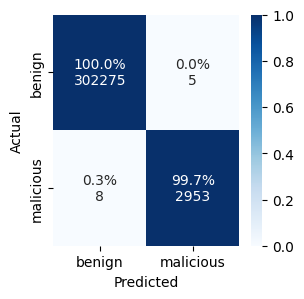

Training time for on all data: 10.2248

Evaluating model: decision_tree_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,5.019877,0.141132,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2368}",244192.000000,"[[241824, 0], [0, 2368]]",0.037598,0.998311,0.996627,1.000000,0.999967,1.000000,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [2, 591]]"
1,6.737171,0.162122,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.043142,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,7.017373,0.149056,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.038373,0.994083,0.993243,0.994924,0.999885,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [4, 588]]"
3,7.001393,0.154964,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.038590,0.996622,0.996622,0.996622,0.999934,0.999967,"{0: 60456, 1: 592}",61048.000000,"[[60454, 2], [2, 590]]"
4,8.675694,0.140208,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.037082,0.994915,0.991554,0.998299,0.999902,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [5, 587]]"
mean,6.890301,0.149497,1.0,1.0,1.0,1.0,1.0,NaN,244192.800000,NaN,0.038957,0.996786,0.995609,0.997969,0.999938,0.999980,NaN,61048.200000,NaN
std,1.297888,0.009297,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.002416,0.002423,0.003293,0.002205,0.000047,0.000022,NaN,0.447214,NaN


Aggregated test confusion matrix:


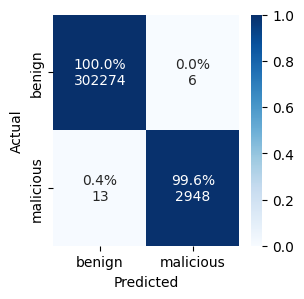

Training time for on all data: 10.4880

Evaluating model: logistic_regression


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,1.633434,0.309521,0.991522,0.987753,0.995319,0.999836,0.999955,"{0: 241824, 1: 2368}",244192.000000,"[[241813, 11], [29, 2339]]",0.070149,0.991525,0.986509,0.996593,0.999836,0.999967,"{0: 60456, 1: 593}",61049.000000,"[[60454, 2], [8, 585]]"
1,2.326628,0.289537,0.993232,0.991136,0.995337,0.999869,0.999955,"{0: 241824, 1: 2369}",244193.000000,"[[241813, 11], [21, 2348]]",0.066005,0.992431,0.996622,0.988275,0.999853,0.999884,"{0: 60456, 1: 592}",61048.000000,"[[60449, 7], [2, 590]]"
2,2.181490,0.304264,0.992797,0.989025,0.996597,0.999861,0.999967,"{0: 241824, 1: 2369}",244193.000000,"[[241816, 8], [26, 2343]]",0.072250,0.990686,0.988176,0.993209,0.999820,0.999934,"{0: 60456, 1: 592}",61048.000000,"[[60452, 4], [7, 585]]"
3,2.469269,0.245832,0.992176,0.990291,0.994068,0.999848,0.999942,"{0: 241824, 1: 2369}",244193.000000,"[[241810, 14], [23, 2346]]",0.044617,0.992379,0.989865,0.994907,0.999853,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [6, 586]]"
4,2.209291,0.275244,0.992379,0.989447,0.995329,0.999853,0.999955,"{0: 241824, 1: 2369}",244193.000000,"[[241813, 11], [25, 2344]]",0.050065,0.988136,0.984797,0.991497,0.999771,0.999917,"{0: 60456, 1: 592}",61048.000000,"[[60451, 5], [9, 583]]"
mean,2.164023,0.284879,0.992421,0.989530,0.995330,0.999853,0.999955,NaN,244192.800000,NaN,0.060617,0.991031,0.989194,0.992896,0.999826,0.999931,NaN,61048.200000,NaN
std,0.317606,0.025603,0.000646,0.001282,0.000894,0.000012,0.000009,NaN,0.447214,NaN,0.012476,0.001769,0.004561,0.003206,0.000034,0.000032,NaN,0.447214,NaN


Aggregated test confusion matrix:


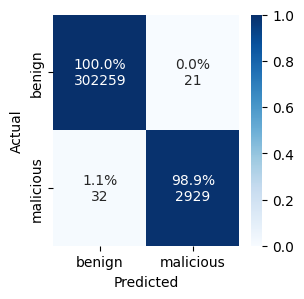

Training time for on all data: 1.3405

Evaluating model: logistic_regression_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,1.848251,0.291725,0.991522,0.987753,0.995319,0.999836,0.999955,"{0: 241824, 1: 2368}",244192.000000,"[[241813, 11], [29, 2339]]",0.076823,0.991525,0.986509,0.996593,0.999836,0.999967,"{0: 60456, 1: 593}",61049.000000,"[[60454, 2], [8, 585]]"
1,2.988798,0.322024,0.993232,0.991136,0.995337,0.999869,0.999955,"{0: 241824, 1: 2369}",244193.000000,"[[241813, 11], [21, 2348]]",0.060856,0.992431,0.996622,0.988275,0.999853,0.999884,"{0: 60456, 1: 592}",61048.000000,"[[60449, 7], [2, 590]]"
2,2.541487,0.338968,0.992797,0.989025,0.996597,0.999861,0.999967,"{0: 241824, 1: 2369}",244193.000000,"[[241816, 8], [26, 2343]]",0.098156,0.990686,0.988176,0.993209,0.999820,0.999934,"{0: 60456, 1: 592}",61048.000000,"[[60452, 4], [7, 585]]"
3,3.280989,0.217941,0.992176,0.990291,0.994068,0.999848,0.999942,"{0: 241824, 1: 2369}",244193.000000,"[[241810, 14], [23, 2346]]",0.055768,0.992379,0.989865,0.994907,0.999853,0.999950,"{0: 60456, 1: 592}",61048.000000,"[[60453, 3], [6, 586]]"
4,2.402700,0.349987,0.992379,0.989447,0.995329,0.999853,0.999955,"{0: 241824, 1: 2369}",244193.000000,"[[241813, 11], [25, 2344]]",0.100568,0.988136,0.984797,0.991497,0.999771,0.999917,"{0: 60456, 1: 592}",61048.000000,"[[60451, 5], [9, 583]]"
mean,2.612445,0.304129,0.992421,0.989530,0.995330,0.999853,0.999955,NaN,244192.800000,NaN,0.078434,0.991031,0.989194,0.992896,0.999826,0.999931,NaN,61048.200000,NaN
std,0.552633,0.052960,0.000646,0.001282,0.000894,0.000012,0.000009,NaN,0.447214,NaN,0.020641,0.001769,0.004561,0.003206,0.000034,0.000032,NaN,0.447214,NaN


Aggregated test confusion matrix:


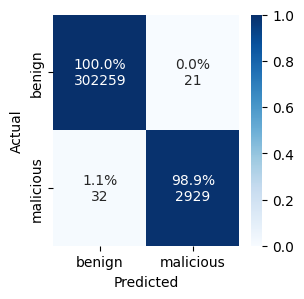

Training time for on all data: 1.5298

Evaluating model: one_rule


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,8.103174,0.067596,0.615648,0.988598,0.447012,0.988030,0.988024,"{0: 241824, 1: 2368}",244192.000000,"[[238928, 2896], [27, 2341]]",0.020672,0.621822,0.989882,0.453282,0.988304,0.988289,"{0: 60456, 1: 593}",61049.000000,"[[59748, 708], [6, 587]]"
1,11.431626,0.066657,0.617697,0.988603,0.449175,0.988128,0.988124,"{0: 241824, 1: 2369}",244193.000000,"[[238952, 2872], [27, 2342]]",0.018016,0.613613,0.989865,0.444613,0.987911,0.987892,"{0: 60456, 1: 592}",61048.000000,"[[59724, 732], [6, 586]]"
2,11.164435,0.072761,0.617841,0.988181,0.449414,0.988141,0.988140,"{0: 241824, 1: 2369}",244193.000000,"[[238956, 2868], [28, 2341]]",0.021237,0.613055,0.991554,0.443689,0.987862,0.987826,"{0: 60456, 1: 592}",61048.000000,"[[59720, 736], [5, 587]]"
3,11.099258,0.071886,0.617756,0.989869,0.448976,0.988116,0.988099,"{0: 241824, 1: 2369}",244193.000000,"[[238946, 2878], [24, 2345]]",0.021092,0.613361,0.984797,0.445378,0.987960,0.987991,"{0: 60456, 1: 592}",61048.000000,"[[59730, 726], [9, 583]]"
4,11.108224,0.072031,0.615445,0.989025,0.446711,0.988009,0.988000,"{0: 241824, 1: 2369}",244193.000000,"[[238922, 2902], [26, 2343]]",0.020514,0.622672,0.988176,0.454545,0.988386,0.988388,"{0: 60456, 1: 592}",61048.000000,"[[59754, 702], [7, 585]]"
mean,10.581343,0.070186,0.616877,0.988855,0.448258,0.988085,0.988077,NaN,244192.800000,NaN,0.020306,0.616904,0.988855,0.448301,0.988085,0.988077,NaN,61048.200000,NaN
std,1.391954,0.002832,0.001218,0.000641,0.001288,0.000061,0.000062,NaN,0.447214,NaN,0.001314,0.004890,0.002563,0.005177,0.000242,0.000248,NaN,0.447214,NaN


Aggregated test confusion matrix:


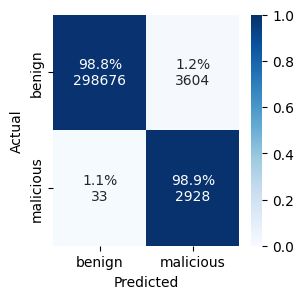

Training time for on all data: 0.1456

Evaluating model: one_rule_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,11.486360,0.109368,0.615648,0.988598,0.447012,0.988030,0.988024,"{0: 241824, 1: 2368}",244192.000000,"[[238928, 2896], [27, 2341]]",0.034267,0.621822,0.989882,0.453282,0.988304,0.988289,"{0: 60456, 1: 593}",61049.000000,"[[59748, 708], [6, 587]]"
1,8.721225,0.130561,0.617697,0.988603,0.449175,0.988128,0.988124,"{0: 241824, 1: 2369}",244193.000000,"[[238952, 2872], [27, 2342]]",0.033930,0.613613,0.989865,0.444613,0.987911,0.987892,"{0: 60456, 1: 592}",61048.000000,"[[59724, 732], [6, 586]]"
2,8.551285,0.121670,0.617841,0.988181,0.449414,0.988141,0.988140,"{0: 241824, 1: 2369}",244193.000000,"[[238956, 2868], [28, 2341]]",0.036770,0.613055,0.991554,0.443689,0.987862,0.987826,"{0: 60456, 1: 592}",61048.000000,"[[59720, 736], [5, 587]]"
3,11.456481,0.119398,0.617756,0.989869,0.448976,0.988116,0.988099,"{0: 241824, 1: 2369}",244193.000000,"[[238946, 2878], [24, 2345]]",0.031314,0.613361,0.984797,0.445378,0.987960,0.987991,"{0: 60456, 1: 592}",61048.000000,"[[59730, 726], [9, 583]]"
4,8.602284,0.132195,0.615445,0.989025,0.446711,0.988009,0.988000,"{0: 241824, 1: 2369}",244193.000000,"[[238922, 2902], [26, 2343]]",0.032767,0.622672,0.988176,0.454545,0.988386,0.988388,"{0: 60456, 1: 592}",61048.000000,"[[59754, 702], [7, 585]]"
mean,9.763527,0.122638,0.616877,0.988855,0.448258,0.988085,0.988077,NaN,244192.800000,NaN,0.033810,0.616904,0.988855,0.448301,0.988085,0.988077,NaN,61048.200000,NaN
std,1.560341,0.009242,0.001218,0.000641,0.001288,0.000061,0.000062,NaN,0.447214,NaN,0.002019,0.004890,0.002563,0.005177,0.000242,0.000248,NaN,0.447214,NaN


Aggregated test confusion matrix:


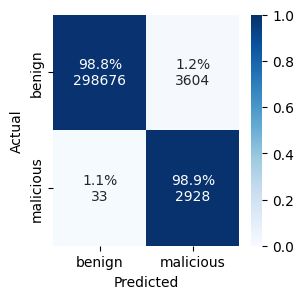

Best feature index: 32
Training time for on all data: 9.3544

Evaluating model: random_forest


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,39.944664,0.611022,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2368}",244192.000000,"[[241824, 0], [0, 2368]]",0.116255,0.999156,0.998314,1.0,0.999984,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [1, 592]]"
1,45.921472,0.432736,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.107021,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,35.656183,0.477694,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.114510,0.997460,0.994932,1.0,0.999951,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
3,38.305176,0.476240,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.118504,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
4,44.062642,0.425044,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.106012,0.998308,0.996622,1.0,0.999967,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [2, 590]]"
mean,40.778027,0.484547,1.0,1.0,1.0,1.0,1.0,NaN,244192.800000,NaN,0.112460,0.998985,0.997974,1.0,0.999980,1.0,NaN,61048.200000,NaN
std,4.191852,0.074727,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.005619,0.001104,0.002203,0.0,0.000021,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


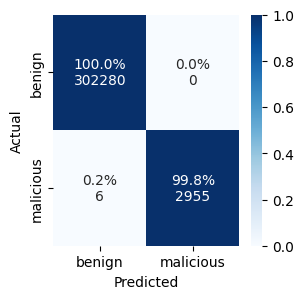

Training time for on all data: 40.1473

Evaluating model: random_forest_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,41.780965,0.509192,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2368}",244192.000000,"[[241824, 0], [0, 2368]]",0.121299,0.999156,0.998314,1.0,0.999984,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [1, 592]]"
1,40.437190,0.537570,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.131015,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,48.793262,0.506130,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.127791,0.997460,0.994932,1.0,0.999951,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
3,50.609789,0.498919,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.126756,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
4,37.753381,0.508508,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.122418,0.997460,0.994932,1.0,0.999951,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
mean,43.874917,0.512064,1.0,1.0,1.0,1.0,1.0,NaN,244192.800000,NaN,0.125856,0.998815,0.997636,1.0,0.999977,1.0,NaN,61048.200000,NaN
std,5.550325,0.014828,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.003992,0.001284,0.002562,0.0,0.000025,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


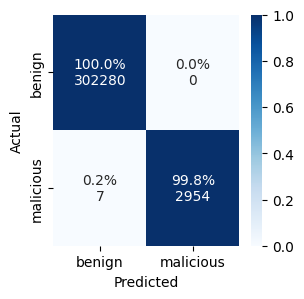

Training time for on all data: 43.0831

Evaluating model: neural_network


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,19.913095,0.384732,1.000000,1.000000,1.0,1.000000,1.0,"{0: 241824, 1: 2368}",244192.000000,"[[241824, 0], [0, 2368]]",0.105097,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [0, 593]]"
1,14.840854,0.455852,0.999578,0.999156,1.0,0.999992,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [2, 2367]]",0.114577,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,17.744140,0.460992,1.000000,1.000000,1.0,1.000000,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.117153,0.998308,0.996622,1.0,0.999967,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [2, 590]]"
3,17.626447,0.441229,1.000000,1.000000,1.0,1.000000,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.102682,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
4,15.842473,0.456218,0.997461,0.994935,1.0,0.999951,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [12, 2357]]",0.110996,0.996610,0.993243,1.0,0.999934,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [4, 588]]"
mean,17.193402,0.439804,0.999408,0.998818,1.0,0.999989,1.0,NaN,244192.800000,NaN,0.110101,0.998984,0.997973,1.0,0.999980,1.0,NaN,61048.200000,NaN
std,1.952374,0.031666,0.001104,0.002202,0.0,0.000021,0.0,NaN,0.447214,NaN,0.006137,0.001516,0.003022,0.0,0.000029,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


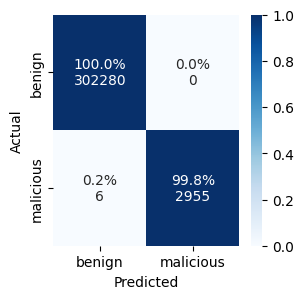

Training time for on all data: 16.5525

Evaluating model: neural_network_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,18.896790,0.397413,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2368}",244192.000000,"[[241824, 0], [0, 2368]]",0.103933,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [0, 593]]"
1,16.161819,0.507626,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.122678,1.000000,1.000000,1.0,1.000000,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,15.407539,0.533147,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.139406,0.998308,0.996622,1.0,0.999967,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [2, 590]]"
3,18.053292,0.498566,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.116213,0.999155,0.998311,1.0,0.999984,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [1, 591]]"
4,20.182141,0.429786,1.0,1.0,1.0,1.0,1.0,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.116060,0.999155,0.998311,1.0,0.999984,1.0,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [1, 591]]"
mean,17.740316,0.473307,1.0,1.0,1.0,1.0,1.0,NaN,244192.800000,NaN,0.119658,0.999323,0.998649,1.0,0.999987,1.0,NaN,61048.200000,NaN
std,1.957766,0.057120,0.0,0.0,0.0,0.0,0.0,NaN,0.447214,NaN,0.012954,0.000708,0.001413,0.0,0.000014,0.0,NaN,0.447214,NaN


Aggregated test confusion matrix:


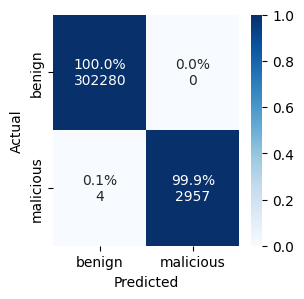

Training time for on all data: 18.4920

Evaluating model: support_vector_machine


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,5.285859,3.182575,0.996399,0.993243,0.999575,0.999930,0.999996,"{0: 241824, 1: 2368}",244192.000000,"[[241823, 1], [16, 2352]]",0.627154,0.995773,0.993255,0.998305,0.999918,0.999983,"{0: 60456, 1: 593}",61049.000000,"[[60455, 1], [4, 589]]"
1,3.577900,2.878627,0.995975,0.992402,0.999575,0.999922,0.999996,"{0: 241824, 1: 2369}",244193.000000,"[[241823, 1], [18, 2351]]",0.661056,0.998311,0.998311,0.998311,0.999967,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [1, 591]]"
2,3.192914,2.313584,0.996614,0.994090,0.999151,0.999934,0.999992,"{0: 241824, 1: 2369}",244193.000000,"[[241822, 2], [14, 2355]]",0.605678,0.995759,0.991554,1.000000,0.999918,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [5, 587]]"
3,3.426437,2.667596,0.996190,0.993246,0.999151,0.999926,0.999992,"{0: 241824, 1: 2369}",244193.000000,"[[241822, 2], [16, 2353]]",0.693394,0.996610,0.993243,1.000000,0.999934,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [4, 588]]"
4,4.894244,3.035597,0.997036,0.994090,1.000000,0.999943,1.000000,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [14, 2355]]",0.574690,0.994907,0.989865,1.000000,0.999902,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [6, 586]]"
mean,4.075471,2.815596,0.996443,0.993414,0.999490,0.999931,0.999995,NaN,244192.800000,NaN,0.632394,0.996272,0.993246,0.999323,0.999928,0.999993,NaN,61048.200000,NaN
std,0.946462,0.339473,0.000408,0.000707,0.000355,0.000008,0.000003,NaN,0.447214,NaN,0.046404,0.001289,0.003160,0.000927,0.000025,0.000009,NaN,0.447214,NaN


Aggregated test confusion matrix:


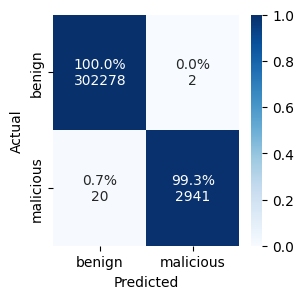

Training time for on all data: 3.5491

Evaluating model: support_vector_machine_vt


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,3.761310,2.752226,0.996399,0.993243,0.999575,0.999930,0.999996,"{0: 241824, 1: 2368}",244192.000000,"[[241823, 1], [16, 2352]]",0.657189,0.995773,0.993255,0.998305,0.999918,0.999983,"{0: 60456, 1: 593}",61049.000000,"[[60455, 1], [4, 589]]"
1,5.636912,3.157943,0.995975,0.992402,0.999575,0.999922,0.999996,"{0: 241824, 1: 2369}",244193.000000,"[[241823, 1], [18, 2351]]",0.656655,0.998311,0.998311,0.998311,0.999967,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [1, 591]]"
2,3.453024,2.283818,0.996614,0.994090,0.999151,0.999934,0.999992,"{0: 241824, 1: 2369}",244193.000000,"[[241822, 2], [14, 2355]]",0.536461,0.995759,0.991554,1.000000,0.999918,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [5, 587]]"
3,3.709789,2.708523,0.996190,0.993246,0.999151,0.999926,0.999992,"{0: 241824, 1: 2369}",244193.000000,"[[241822, 2], [16, 2353]]",0.645919,0.996610,0.993243,1.000000,0.999934,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [4, 588]]"
4,5.178309,3.015844,0.997036,0.994090,1.000000,0.999943,1.000000,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [14, 2355]]",0.611114,0.994907,0.989865,1.000000,0.999902,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [6, 586]]"
mean,4.347869,2.783671,0.996443,0.993414,0.999490,0.999931,0.999995,NaN,244192.800000,NaN,0.621467,0.996272,0.993246,0.999323,0.999928,0.999993,NaN,61048.200000,NaN
std,0.987827,0.335586,0.000408,0.000707,0.000355,0.000008,0.000003,NaN,0.447214,NaN,0.051101,0.001289,0.003160,0.000927,0.000025,0.000009,NaN,0.447214,NaN


Aggregated test confusion matrix:


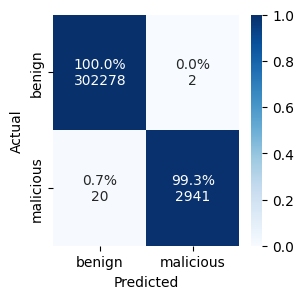

Training time for on all data: 3.7609



In [7]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in available_models:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate(ml_pipeline, X, y, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    if model_name == 'one_rule':
        # Prevent information leakage by using the best rule from the cross evaluation
        models[model_name] = ml_pipeline.fit(X, y, clf__feature_idx=32)
    else:
        models[model_name] = ml_pipeline.fit(X, y)
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()

Evaluating model: hist_gradient_boosting


,fit_time,pred_train_time,train_f1,train_recall,train_precision,train_accuracy,train_tnr,train_samples,n_samples_train,train_conf_matrix,pred_test_time,test_f1,test_recall,test_precision,test_accuracy,test_tnr,test_samples,n_samples_test,test_conf_matrix
0,10.762524,1.555716,0.999366,0.998733,1.000000,0.999988,1.000000,"{0: 241824, 1: 2368}",244192.000000,"[[241824, 0], [3, 2365]]",0.477011,0.999156,0.998314,1.000000,0.999984,1.000000,"{0: 60456, 1: 593}",61049.000000,"[[60456, 0], [1, 592]]"
1,18.276342,1.723681,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.477686,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
2,19.167755,1.635553,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [0, 2369]]",0.321030,0.997460,0.994932,1.000000,0.999951,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [3, 589]]"
3,11.609036,1.957228,0.999789,0.999578,1.000000,0.999996,1.000000,"{0: 241824, 1: 2369}",244193.000000,"[[241824, 0], [1, 2368]]",0.480183,1.000000,1.000000,1.000000,1.000000,1.000000,"{0: 60456, 1: 592}",61048.000000,"[[60456, 0], [0, 592]]"
4,15.516102,1.793371,0.999789,1.000000,0.999578,0.999996,0.999996,"{0: 241824, 1: 2369}",244193.000000,"[[241823, 1], [0, 2369]]",0.310841,0.996616,0.994932,0.998305,0.999934,0.999983,"{0: 60456, 1: 592}",61048.000000,"[[60455, 1], [3, 589]]"
mean,15.066352,1.733110,0.999789,0.999662,0.999916,0.999996,0.999999,NaN,244192.800000,NaN,0.413350,0.998646,0.997636,0.999661,0.999974,0.999997,NaN,61048.200000,NaN
std,3.801440,0.154058,0.000259,0.000551,0.000189,0.000005,0.000002,NaN,0.447214,NaN,0.089008,0.001537,0.002562,0.000758,0.000030,0.000007,NaN,0.447214,NaN


Aggregated test confusion matrix:


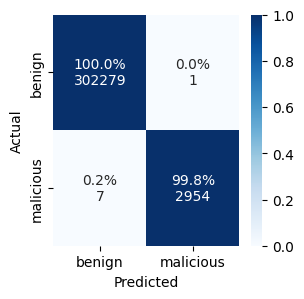

Training time for on all data: 9.1891



In [15]:
# Split the data in train and test
# Do Stratified K-fold cross validation (n=5), afterwards train model on all data and save to disk. 
s_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

models = {}

for model_name in ['hist_gradient_boosting']:
    print("Evaluating model: {}".format(model_name))

    # Cross evaluate the selected model
    ml_pipeline = get_model(model_name)
    results = cross_evaluate(ml_pipeline, X, y, s_kfold, metrics_func=evaluate_predictions, n_jobs=5)
    results.to_csv(f"{result_dir}/{model_name}_results.csv", index=True)
    results.to_pickle(f"{result_dir}/{model_name}_results.p")
    display(results)

    # Plot the aggregated confusion matrix over all test folds
    print("Aggregated test confusion matrix:")
    agg_conf_matrix = np.sum([np.array(matrix) for matrix in results['test_conf_matrix'].dropna()], axis=0)
    plt = plot_confusion_matrix(agg_conf_matrix, figsize=(3,3))
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.png", format='png', bbox_inches='tight')
    plt.savefig(f"{result_dir}/{model_name}_conf_matrix.eps", format='eps', bbox_inches='tight')
    plt.show()

    # Train the model on all data
    start_time = time.time()
    if model_name == 'one_rule':
        # Prevent information leakage by using the best rule from the cross evaluation
        models[model_name] = ml_pipeline.fit(X, y, clf__feature_idx=32)
    else:
        models[model_name] = ml_pipeline.fit(X, y)
    training_time = time.time() - start_time
    print("Training time for on all data: {:.4f}".format(training_time))

    # Save the model
    f = open(f"{result_dir}/{model_name}.p", "wb")
    pickle.dump(models[model_name], f)
    f.close()
    print()